# IPL Exploratory Data Analysis (2008–2024)

Questions this notebook answers (Phase 1 of the project plan):

1. Does winning the toss help?
2. Win rates by team and by venue, and how often chasing teams win at each venue.
3. Typical first-innings scores by venue and by season — has scoring changed?
4. Top players by runs, strike rate, wickets and economy (with minimum samples).
5. How win probability behaves over the course of a chase.

**Data**: Kaggle IPL `matches.csv` + `deliveries.csv` (1,095 matches, 260,920
deliveries), cleaned by `src/data.py` (canonical team/venue names, corrected
wicket flags, season normalisation). Ties and no-result matches are excluded
from chase-level analysis. This project is for learning only — **not** for
betting or gambling.

## Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import clean_deliveries, clean_matches, load_deliveries, load_matches

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

matches = clean_matches(load_matches())
deliveries = clean_deliveries(load_deliveries())
matches["toss_win"] = matches["toss_winner"] == matches["winner"]
print(f"matches: {matches.shape}, deliveries: {deliveries.shape}")
print(f"seasons: {matches['season_year'].min()}-{matches['season_year'].max()}")
print("no-result matches:", int(matches["is_no_result"].sum()),
      "| ties (super over):", int(matches["is_tie"].sum()))

matches: (1095, 25), deliveries: (260920, 20)
seasons: 2008-2024
no-result matches: 5 | ties (super over): 14


## 1. Does winning the toss help?

We look at P(match won | toss won) overall, per season, per toss decision and
per venue. A useful reference: if the toss were irrelevant the rate would be
0.5 (ties excluded from the per-split view below for clarity).

P(win | toss won) overall = 0.509 +/- 0.030 (95% CI, n=1076 matches)


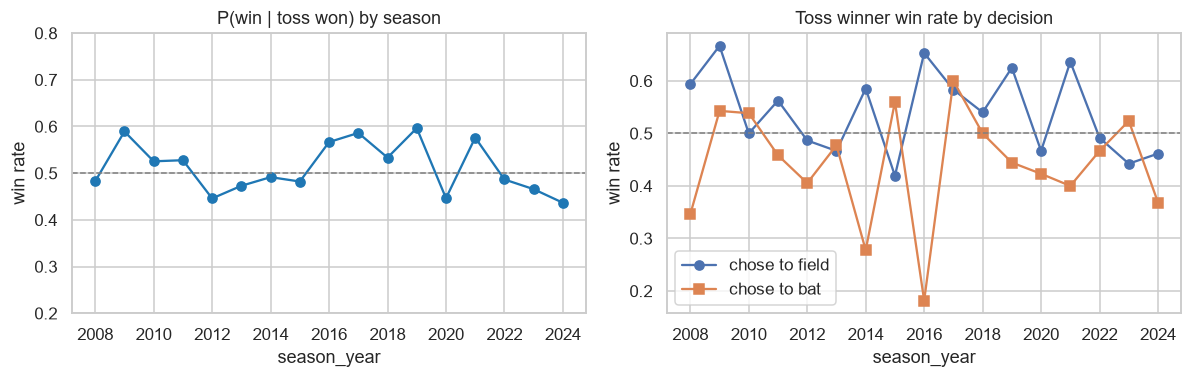

                mean       
toss_decision    bat  field
season_year                
2017           0.600  0.583
2018           0.500  0.540
2019           0.444  0.625
2020           0.423  0.467
2021           0.400  0.636
2022           0.467  0.492
2023           0.524  0.442
2024           0.368  0.462


In [2]:
completed = matches[~matches["is_no_result"] & ~matches["is_tie"]].copy()

rate = completed["toss_win"].mean()
n = len(completed)
ci = 1.96 * np.sqrt(rate * (1 - rate) / n)
print(f"P(win | toss won) overall = {rate:.3f} +/- {ci:.3f} (95% CI, n={n} matches)")

season_toss = completed.groupby("season_year")["toss_win"].agg(["mean", "size"])
decision = (completed.groupby(["season_year", "toss_decision"])["toss_win"]
            .agg(["mean", "size"]).unstack("toss_decision"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
season_toss["mean"].plot(ax=axes[0], marker="o", color="#1f77b4")
axes[0].axhline(0.5, color="grey", ls="--", lw=1)
axes[0].set_title("P(win | toss won) by season")
axes[0].set_ylabel("win rate")
axes[0].set_ylim(0.2, 0.8)
decision[("mean", "field")].plot(ax=axes[1], marker="o", label="chose to field")
decision[("mean", "bat")].plot(ax=axes[1], marker="s", label="chose to bat")
axes[1].axhline(0.5, color="grey", ls="--", lw=1)
axes[1].set_title("Toss winner win rate by decision")
axes[1].set_ylabel("win rate")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG / "toss_by_season.png", bbox_inches="tight")
plt.show()
print(decision[["mean"]].round(3).tail(8))

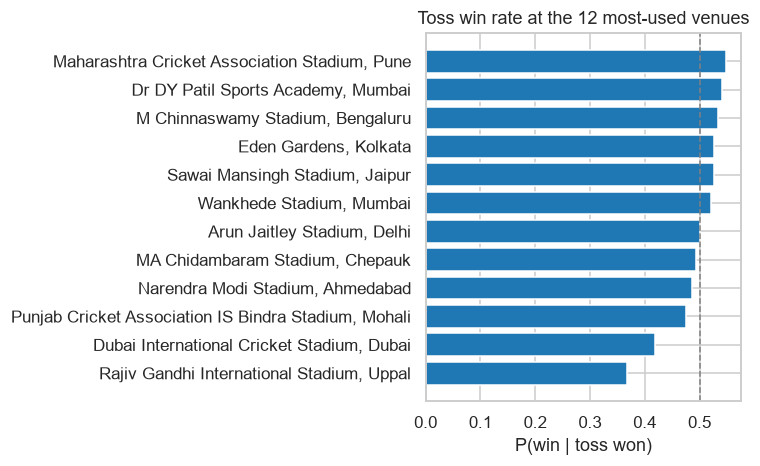

                                                     mean  size
venue                                                          
Rajiv Gandhi International Stadium, Uppal           0.368    76
Dubai International Cricket Stadium, Dubai          0.419    43
Punjab Cricket Association IS Bindra Stadium, M...  0.475    61
Narendra Modi Stadium, Ahmedabad                    0.486    35
MA Chidambaram Stadium, Chepauk                     0.494    83
Arun Jaitley Stadium, Delhi                         0.500    88
Wankhede Stadium, Mumbai                            0.521   117
Sawai Mansingh Stadium, Jaipur                      0.526    57
Eden Gardens, Kolkata                               0.527    93
M Chinnaswamy Stadium, Bengaluru                    0.533    90
Dr DY Patil Sports Academy, Mumbai                  0.541    37
Maharashtra Cricket Association Stadium, Pune       0.549    51


In [3]:
top_venues = completed["venue"].value_counts().head(12).index
venue_toss = (completed[completed["venue"].isin(top_venues)]
              .groupby("venue")["toss_win"].agg(["mean", "size"])
              .sort_values("mean"))
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(venue_toss.index, venue_toss["mean"], color="#1f77b4")
ax.axvline(0.5, color="grey", ls="--", lw=1)
ax.set_xlabel("P(win | toss won)")
ax.set_title("Toss win rate at the 12 most-used venues")
fig.tight_layout()
fig.savefig(FIG / "toss_by_venue.png", bbox_inches="tight")
plt.show()
print(venue_toss.round(3))

## 2. Win rates by team and by venue

Team win rates over all completed matches (canonical franchise names, so e.g.
Deccan Chargers count as Sunrisers Hyderabad). For venues we ask how often the
**chasing** team wins — the quantity our model predicts.

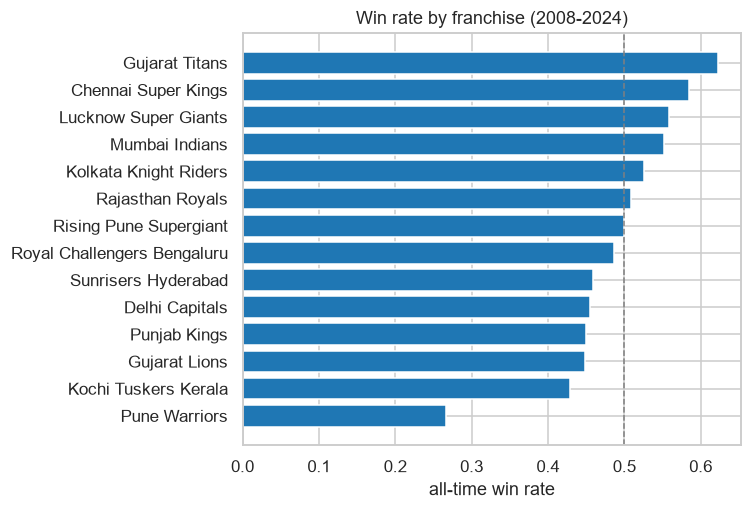

                      played  won  win_rate
Mumbai Indians           257  142     0.553
Lucknow Super Giants      43   24     0.558
Chennai Super Kings      236  138     0.585
Gujarat Titans            45   28     0.622
                      played  won  win_rate
Pune Warriors             45   12     0.267
Kochi Tuskers Kerala      14    6     0.429
Gujarat Lions             29   13     0.448


In [4]:
played = pd.concat([
    completed.groupby("team1").size(),
    completed.groupby("team2").size(),
]).groupby(level=0).sum().rename("played")
won = completed.groupby("winner").size().rename("won")
team_stats = pd.concat([played, won], axis=1).fillna(0)
team_stats["win_rate"] = team_stats["won"] / team_stats["played"]
team_stats = team_stats.sort_values("win_rate")

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(team_stats.index, team_stats["win_rate"], color="#1f77b4")
ax.axvline(0.5, color="grey", ls="--", lw=1)
ax.set_xlabel("all-time win rate")
ax.set_title("Win rate by franchise (2008-2024)")
fig.tight_layout()
fig.savefig(FIG / "team_win_rates.png", bbox_inches="tight")
plt.show()
print(team_stats.round(3).tail(4))
print(team_stats.round(3).head(3))

overall chase win rate: 0.543 (584 of 1076 matches)


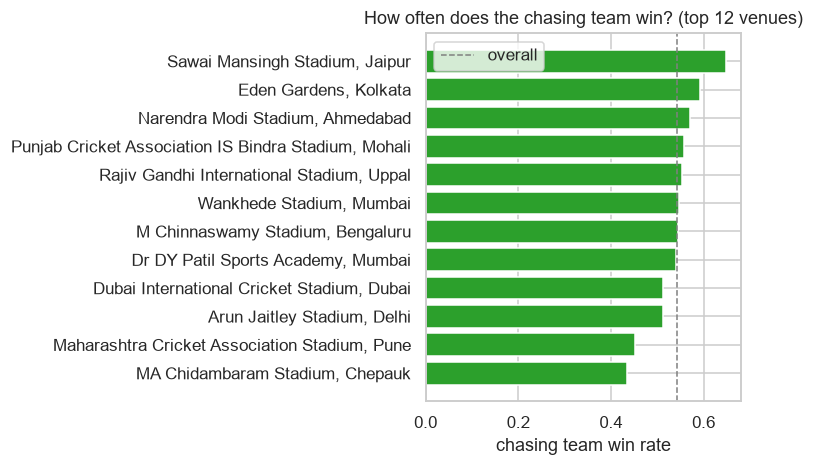

                                                     mean  size
venue                                                          
MA Chidambaram Stadium, Chepauk                     0.434    83
Maharashtra Cricket Association Stadium, Pune       0.451    51
Arun Jaitley Stadium, Delhi                         0.511    88
Dubai International Cricket Stadium, Dubai          0.512    43
Dr DY Patil Sports Academy, Mumbai                  0.541    37
M Chinnaswamy Stadium, Bengaluru                    0.544    90
Wankhede Stadium, Mumbai                            0.547   117
Rajiv Gandhi International Stadium, Uppal           0.553    76
Punjab Cricket Association IS Bindra Stadium, M...  0.557    61
Narendra Modi Stadium, Ahmedabad                    0.571    35
Eden Gardens, Kolkata                               0.591    93
Sawai Mansingh Stadium, Jaipur                      0.649    57


In [5]:
chasing = deliveries[deliveries["inning"] == 2].groupby("match_id")["batting_team"].first()
chase = completed.set_index("id").join(chasing.rename("chasing_team"))
chase["chase_won"] = chase["winner"] == chase["chasing_team"]
print(f"overall chase win rate: {chase['chase_won'].mean():.3f} "
      f"({int(chase['chase_won'].sum())} of {len(chase)} matches)")

venue_chase = (chase[chase["venue"].isin(top_venues)]
               .groupby("venue")["chase_won"].agg(["mean", "size"])
               .sort_values("mean"))
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(venue_chase.index, venue_chase["mean"], color="#2ca02c")
ax.axvline(chase["chase_won"].mean(), color="grey", ls="--", lw=1, label="overall")
ax.set_xlabel("chasing team win rate")
ax.set_title("How often does the chasing team win? (top 12 venues)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "chase_win_by_venue.png", bbox_inches="tight")
plt.show()
print(venue_chase.round(3))

## 3. First-innings scores: by season and by venue

Has scoring changed over 17 seasons? (DLS-shortened innings are included in
venue/season aggregates; totals are runs off the bat plus extras.)

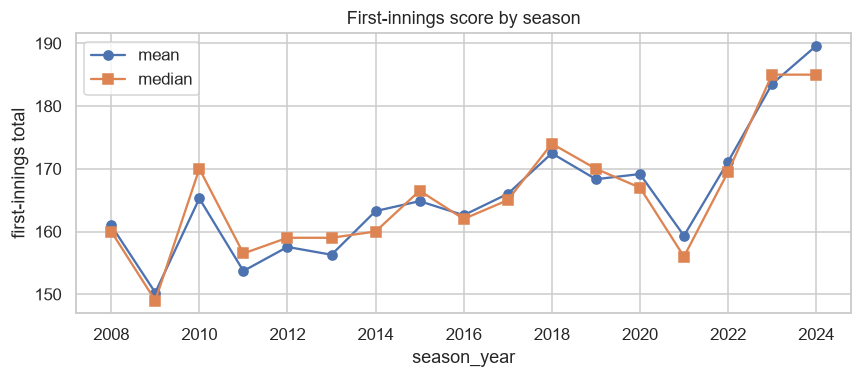

season_year   2008   2009   2010   2011   2012   2013   2014   2015   2016  \
mean         161.0  150.3  165.3  153.7  157.5  156.3  163.3  164.8  162.6   
median       160.0  149.0  170.0  156.5  159.0  159.0  160.0  166.5  162.0   

season_year   2017   2018   2019   2020   2021   2022   2023   2024  
mean         166.0  172.5  168.3  169.2  159.3  171.1  183.5  189.6  
median       165.0  174.0  170.0  167.0  156.0  169.5  185.0  185.0  
2008 mean: 161.0 -> 2024 mean: 189.6


In [6]:
i1 = deliveries[deliveries["inning"] == 1].groupby("match_id")["total_runs"].sum()
totals = completed.set_index("id").join(i1.rename("i1_total"))

by_season = totals.groupby("season_year")["i1_total"].agg(["mean", "median"])
fig, ax = plt.subplots(figsize=(8, 3.6))
by_season["mean"].plot(ax=ax, marker="o", label="mean")
by_season["median"].plot(ax=ax, marker="s", label="median")
ax.set_ylabel("first-innings total")
ax.set_title("First-innings score by season")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "first_innings_trend.png", bbox_inches="tight")
plt.show()
print(by_season.round(1).T)
print(f"2008 mean: {by_season.loc[2008, 'mean']:.1f} -> 2024 mean: {by_season.loc[2024, 'mean']:.1f}")

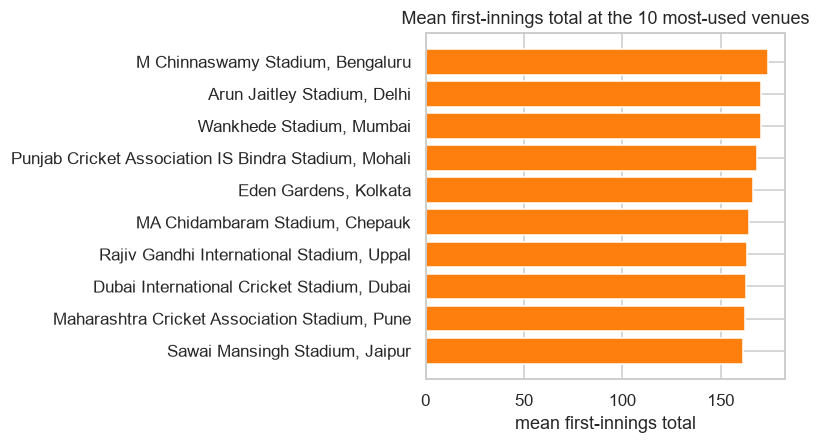

venue
Sawai Mansingh Stadium, Jaipur                          161.5
Maharashtra Cricket Association Stadium, Pune           162.4
Dubai International Cricket Stadium, Dubai              162.8
Rajiv Gandhi International Stadium, Uppal               163.3
MA Chidambaram Stadium, Chepauk                         164.3
Eden Gardens, Kolkata                                   166.3
Punjab Cricket Association IS Bindra Stadium, Mohali    168.3
Wankhede Stadium, Mumbai                                170.3
Arun Jaitley Stadium, Delhi                             170.4
M Chinnaswamy Stadium, Bengaluru                        174.2
Name: i1_total, dtype: float64


In [7]:
top10 = totals["venue"].value_counts().head(10).index
venue_scores = totals[totals["venue"].isin(top10)].groupby("venue")["i1_total"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.barh(venue_scores.index, venue_scores, color="#ff7f0e")
ax.set_xlabel("mean first-innings total")
ax.set_title("Mean first-innings total at the 10 most-used venues")
fig.tight_layout()
fig.savefig(FIG / "first_innings_by_venue.png", bbox_inches="tight")
plt.show()
print(venue_scores.round(1))

## 4. Player leaders (with minimum-sample thresholds)

- Runs: all batters. Strike rate: min 500 legal balls faced.
- Wickets: bowler-credited dismissals only (run outs, retired hurt/out and
  obstructing-the-field are excluded). Economy: min 300 legal balls (50 overs).
- Economy counts runs a bowler is charged with: batsman runs + wides + no-balls.

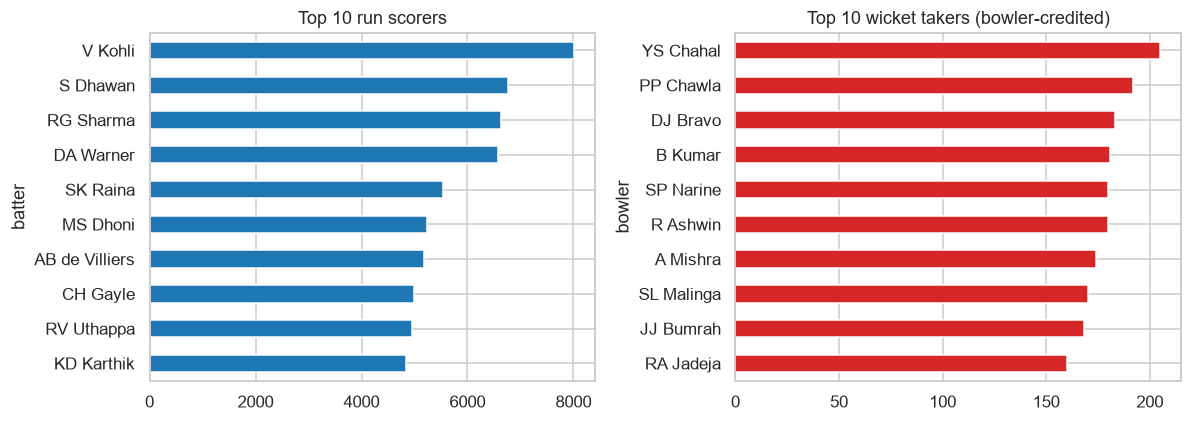

TOP RUN SCORERS
           runs  balls  strike_rate
batter                             
V Kohli    8014   6051        132.4
S Dhawan   6769   5304        127.6
RG Sharma  6630   5039        131.6
DA Warner  6567   4682        140.3
SK Raina   5536   4025        137.5

BEST STRIKE RATE (min 500 legal balls)
                runs  balls  strike_rate
batter                                  
AD Russell      2488   1407        176.8
H Klaasen        993    584        170.0
SP Narine       1534    924        166.0
LS Livingstone   939    571        164.4
N Pooran        1769   1090        162.3

TOP WICKET TAKERS
bowler
YS Chahal    205
PP Chawla    192
DJ Bravo     183
B Kumar      181
R Ashwin     180
Name: wickets, dtype: int64

BEST ECONOMY (min 300 legal balls)
                  runs  wickets  legal_balls  economy
bowler                                               
A Kumble          1058     45.0          965     6.58
GD McGrath         357     12.0          324     6.61
M Muralitharan

In [8]:
bat = deliveries.groupby("batter").agg(runs=("batsman_runs", "sum"), balls=("is_legal_ball", "sum"))
bat["strike_rate"] = bat["runs"] / bat["balls"] * 100

bowler_wicket = (deliveries["is_out"]
                 & ~deliveries["dismissal_kind"].isin(
                     ["run out", "retired hurt", "retired out", "obstructing the field"]))
wkts = deliveries[bowler_wicket].groupby("bowler").size().rename("wickets")
legal = deliveries[deliveries["is_legal_ball"]].groupby("bowler").size().rename("legal_balls")
charged = deliveries["batsman_runs"] + deliveries["extra_runs"].where(
    deliveries["extras_type"].isin(["wides", "noballs"]), 0)
bowling = pd.concat([
    deliveries.assign(runs=charged).groupby("bowler")["runs"].sum().rename("runs"),
    wkts, legal], axis=1).dropna()
bowling["economy"] = bowling["runs"] / (bowling["legal_balls"] / 6)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bat["runs"].sort_values().tail(10).plot.barh(ax=axes[0], color="#1f77b4")
axes[0].set_title("Top 10 run scorers")
wkts.sort_values().tail(10).plot.barh(ax=axes[1], color="#d62728")
axes[1].set_title("Top 10 wicket takers (bowler-credited)")
fig.tight_layout()
fig.savefig(FIG / "top_players.png", bbox_inches="tight")
plt.show()

print("TOP RUN SCORERS"); print(bat.sort_values("runs", ascending=False).head(5).round(1))
qualified_sr = bat[bat["balls"] >= 500]
print("\nBEST STRIKE RATE (min 500 legal balls)")
print(qualified_sr.sort_values("strike_rate", ascending=False).head(5).round(1))
print("\nTOP WICKET TAKERS"); print(wkts.sort_values(ascending=False).head(5))
qualified_eco = bowling[bowling["legal_balls"] >= 300]
print("\nBEST ECONOMY (min 300 legal balls)")
print(qualified_eco.sort_values("economy").head(5).round(2))

## 5. Win probability over the course of a chase

Before any model: the **empirical** chance that a chase succeeds, as a
function of the required run rate (RRR) at that moment, split by stage of the
innings. Each point uses only information available at that ball.

stage       overs 1-6  overs 7-15  overs 16-20
rrr_bucket                                    
3.0             0.967       0.978        0.994
7.0             0.764       0.826        0.931
9.0             0.541       0.607        0.714
11.0            0.222       0.333        0.560
13.5            0.075       0.152        0.310
25.0            0.031       0.022        0.072


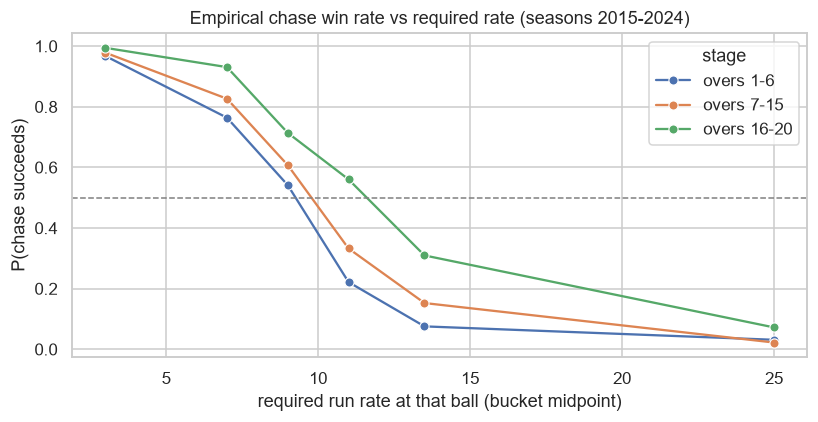

In [9]:
from src.features import build_chase_features

feats = build_chase_features(matches, deliveries)
feats = feats[feats["season_year"] >= 2015]  # recent-era chases only
feats["rrr_bucket"] = pd.cut(feats["rrr"], [0, 6, 8, 10, 12, 15, 36], right=False,
                             labels=[3, 7, 9, 11, 13.5, 25])  # bucket midpoints
feats["stage"] = pd.cut(feats["balls_bowled"], [0, 36, 90, 120],
                        labels=["overs 1-6", "overs 7-15", "overs 16-20"])
emp = (feats.groupby(["rrr_bucket", "stage"], observed=True)["chase_won"]
       .agg(win_rate="mean", n="size").reset_index())
print(emp.pivot(index="rrr_bucket", columns="stage", values="win_rate").round(3))

fig, ax = plt.subplots(figsize=(7.6, 4))
sns.lineplot(data=emp, x="rrr_bucket", y="win_rate", hue="stage", marker="o", ax=ax)
ax.axhline(0.5, color="grey", ls="--", lw=1)
ax.set_xlabel("required run rate at that ball (bucket midpoint)")
ax.set_ylabel("P(chase succeeds)")
ax.set_title("Empirical chase win rate vs required rate (seasons 2015-2024)")
fig.tight_layout()
fig.savefig(FIG / "chase_rrr_curve.png", bbox_inches="tight")
plt.show()

## Key findings

1. **The toss is close to irrelevant overall.** Toss winners won 50.9% of
   1,076 completed matches (95% CI 47.9-53.9%, which includes 50%); the
   decision's apparent edge swings by season (field-first won 63.6% in 2021
   but 44.2% in 2023).
2. **Venues differ wildly for chasing - 21 percentage points.** Chasing teams
   win 64.9% of matches in Jaipur but only 43.4% at Chepauk (54.3% overall).
   This is why venue carries the largest share of the model's importance.
3. **Scoring has risen about 29 runs per first innings.** The mean
   first-innings total went from 161.0 (2008) to 189.6 (2024), with the
   biggest jump in the 2023-24 impact-player era (171.1 in 2022, 183.5 in
   2023, 189.6 in 2024).
4. **Player leaders (with minimum samples).** V Kohli leads runs with 8,014
   (SR 132.4); AD Russell has the best strike rate, 176.8 (min 500 legal
   balls); YS Chahal the most bowler-credited wickets, 205; A Kumble the best
   economy, 6.58 (min 50 overs).
5. **The same required rate means very different things at different stages.**
   At RRR about 11, chases succeed 22.2% of the time in overs 1-6 but 56.0%
   in overs 16-20 - so model quality must be reported stage by stage.

In [10]:
rate = completed["toss_win"].mean()
ci = 1.96 * np.sqrt(rate * (1 - rate) / len(completed))
print(f"1. toss: P(win|toss won) = {rate:.3f} +/- {ci:.3f}")
print(f"2. chases: overall {chase['chase_won'].mean():.3f}; "
      f"Jaipur {venue_chase.loc['Sawai Mansingh Stadium, Jaipur', 'mean']:.3f} vs "
      f"Chepauk {venue_chase.loc['MA Chidambaram Stadium, Chepauk', 'mean']:.3f}")
print(f"3. scoring: {by_season.loc[2008, 'mean']:.1f} (2008) -> {by_season.loc[2024, 'mean']:.1f} (2024) mean first-innings total")
print(f"4. players: Kohli {int(bat.loc['V Kohli', 'runs'])} runs | Russell SR {bat.loc['AD Russell', 'strike_rate']:.1f} "
      f"| Chahal {int(wkts['YS Chahal'])} wickets | Kumble economy {bowling.loc['A Kumble', 'economy']:.2f}")
r11 = emp[emp["rrr_bucket"] == 11].set_index("stage")["win_rate"]
print(f"5. stage effect at RRR~11: overs 1-6 {r11['overs 1-6']:.3f} vs overs 16-20 {r11['overs 16-20']:.3f}")

1. toss: P(win|toss won) = 0.509 +/- 0.030
2. chases: overall 0.543; Jaipur 0.649 vs Chepauk 0.434
3. scoring: 161.0 (2008) -> 189.6 (2024) mean first-innings total
4. players: Kohli 8014 runs | Russell SR 176.8 | Chahal 205 wickets | Kumble economy 6.58
5. stage effect at RRR~11: overs 1-6 0.222 vs overs 16-20 0.560
